In [4]:
import matplotlib
import numpy as np
import pandas as pd


In [5]:
df = pd.read_csv("data/Airline_Delay_Cause.csv")

df.head()


,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2026,8,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",62.0,5.0,1.48,0.19,...,0.0,1.77,1.0,0.0,360.0,160.0,11.0,56.0,0.0,133.0
1,2026,8,9E,Endeavor Air Inc.,ABY,"Albany, GA: Southwest Georgia Regional",93.0,17.0,3.54,0.70,...,0.0,9.02,1.0,1.0,1585.0,366.0,89.0,238.0,0.0,892.0
2,2026,8,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",93.0,21.0,4.61,1.25,...,0.0,10.57,0.0,0.0,1552.0,207.0,58.0,317.0,0.0,970.0
3,2026,8,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",214.0,54.0,15.65,4.51,...,0.0,25.77,1.0,0.0,4226.0,1393.0,290.0,398.0,0.0,2145.0
4,2026,8,9E,Endeavor Air Inc.,ALB,"Albany, NY: Albany International",90.0,14.0,3.51,0.00,...,0.0,9.94,3.0,0.0,1238.0,220.0,0.0,119.0,0.0,899.0


## 0. What one row is (read this before any chart)

This is the BTS *Airline On-Time Performance — Delay Cause* table. **One row = one carrier at one arrival airport in one month**, not one flight.

- Coverage: **Jan 2023 → Aug 2026** (2026 is partial — 8 months). Any "by month" view must average across years, not sum, or Jan–Aug get an extra year.
- A flight is "delayed" when it arrives **≥15 min late** (`arr_del15`). Cancelled/diverted flights are **not** counted as delayed.
- The five `*_ct` columns split each delayed flight across causes by minutes (hence decimals); they sum exactly to `arr_del15`. The five `*_delay` columns sum to `arr_delay` (minutes).
- Cause definitions (BTS): **carrier** = within the airline's control (crew, maintenance, cleaning, fueling…); **weather** = *extreme* weather only; **NAS** = National Aviation System (ATC, airport congestion, *non-extreme* weather, heavy traffic); **security**; **late aircraft** = the inbound plane arrived late (a knock-on effect).
- Airport = the **arrival** airport. A delay counted at SFO may have started in Denver.

In [ ]:
import matplotlib.pyplot as plt

df = df.dropna(subset=["arr_flights"]).fillna({"arr_del15": 0})  # 72 empty rows (2026)
df["date"] = pd.to_datetime(dict(year=df.year, month=df.month, day=1))

CAUSES = ["carrier", "weather", "nas", "security", "late_aircraft"]
LABELS = {"carrier": "Carrier", "weather": "Extreme weather", "nas": "NAS (ATC / congestion)",
          "security": "Security", "late_aircraft": "Late aircraft"}
# Fixed colour per cause (colour follows the entity, everywhere) — CVD-validated order
COLORS = {"carrier": "#2a78d6", "weather": "#eb6834", "nas": "#1baf7a",
          "security": "#eda100", "late_aircraft": "#e87ba4"}
MINS = [c + "_delay" for c in CAUSES]
CTS = [c + "_ct" for c in CAUSES]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "axes.edgecolor": "#9a9993", "font.size": 10,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left"})

print(f"{df.arr_flights.sum():,.0f} arrivals | {df.arr_del15.sum()/df.arr_flights.sum():.1%} delayed ≥15 min "
      f"| {df.arr_cancelled.sum()/df.arr_flights.sum():.2%} cancelled")


27,790,201 arrivals | 21.1% delayed ≥15 min | 1.56% cancelled


## RQ1 — What is the biggest cause of flight delays?

Two ways to measure "biggest": **how many** delayed flights a cause touches, and **how many minutes** it costs. Then a third, sharper view: *late aircraft* isn't a root cause — it's a delay passed down from an earlier flight. Redistributing it gives a "root cause" view.

,flights,minutes,share_flights,share_minutes,avg_min_per_delay,root_share
late_aircraft,2172790.3,172792818.0,37.0,40.5,79.5,NaN
carrier,1854669.4,143275874.0,31.6,33.6,77.3,56.4
nas,1606379.7,83934898.0,27.4,19.7,52.3,33.1
weather,221318.1,26021153.0,3.8,6.1,117.6,10.2
security,13907.6,670594.0,0.2,0.2,48.2,0.3


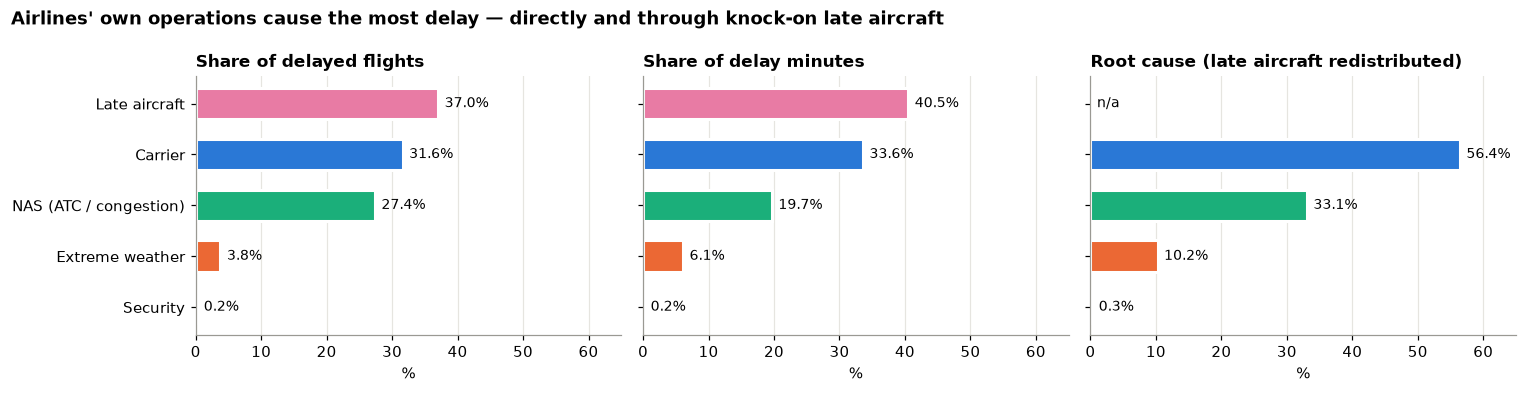

In [ ]:
tot = pd.DataFrame({"flights": df[CTS].sum().values, "minutes": df[MINS].sum().values}, index=CAUSES)
tot["share_flights"] = tot.flights / tot.flights.sum() * 100
tot["share_minutes"] = tot.minutes / tot.minutes.sum() * 100
tot["avg_min_per_delay"] = tot.minutes / tot.flights
root = tot.minutes.drop("late_aircraft")
tot["root_share"] = (root / root.sum() * 100).reindex(CAUSES)
display(tot.round(1).sort_values("share_minutes", ascending=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
panels = [("share_flights", "Share of delayed flights"), ("share_minutes", "Share of delay minutes"),
          ("root_share", "Root cause (late aircraft redistributed)")]
order = tot.sort_values("share_minutes").index
for ax, (col, title) in zip(axes, panels):
    vals = tot.loc[order, col]
    ax.barh([LABELS[c] for c in order], vals.fillna(0), color=[COLORS[c] for c in order], height=0.62,
            edgecolor="white", linewidth=2)
    for i, v in enumerate(vals):
        ax.text((0 if pd.isna(v) else v) + 1, i, "n/a" if pd.isna(v) else f"{v:.1f}%", va="center", fontsize=9)
    ax.set_title(title, fontsize=11); ax.set_xlim(0, 65); ax.grid(axis="y", visible=False)
    ax.set_xlabel("%")
fig.suptitle("Airlines' own operations cause the most delay — directly and through knock-on late aircraft",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()


**Takeaways**
- Raw answer: **late aircraft** (37% of delayed flights, 40% of minutes) — but that's a symptom, not a cause.
- Root-cause answer: **carrier** issues (~56%), then **NAS** (~33%). Extreme weather is only ~10%.
- Weather delays are rare but long (~118 min each vs ~52 for NAS) — a "severity" angle worth a chart of its own.
- ⚠️ Caveat for the dashboard: BTS files *non-extreme* weather under NAS, so "weather" is understated. Say this in a footnote.

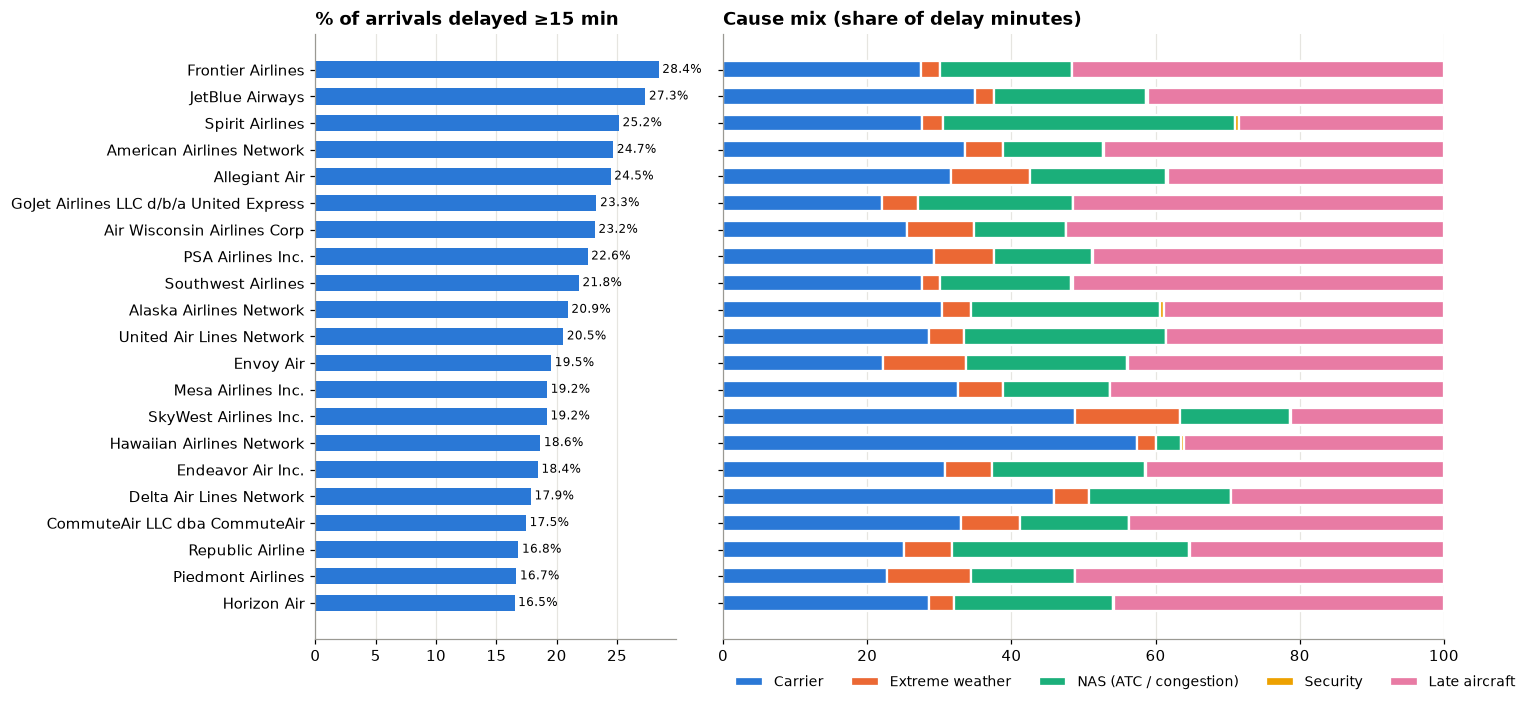

In [ ]:
# Does the answer depend on the airline? Cause mix (share of minutes) by carrier
car = df.groupby("carrier_name")[["arr_flights", "arr_del15", "arr_cancelled"] + MINS].sum()
car["delay_rate"] = car.arr_del15 / car.arr_flights * 100
car = car.sort_values("delay_rate")
mix = car[MINS].div(car[MINS].sum(axis=1), axis=0) * 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True, gridspec_kw={"width_ratios": [1, 2]})
a1.barh(car.index, car.delay_rate, color="#2a78d6", height=0.62)
for i, v in enumerate(car.delay_rate):
    a1.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=8)
a1.set_title("% of arrivals delayed ≥15 min"); a1.grid(axis="y", visible=False)
left = np.zeros(len(mix))
for c, m in zip(CAUSES, MINS):
    a2.barh(mix.index, mix[m], left=left, color=COLORS[c], label=LABELS[c], height=0.62,
            edgecolor="white", linewidth=1.5)
    left += mix[m].values
a2.set_title("Cause mix (share of delay minutes)"); a2.set_xlim(0, 100); a2.grid(axis="y", visible=False)
a2.legend(ncol=5, loc="upper left", bbox_to_anchor=(0, -0.04), frameon=False, fontsize=9)
plt.tight_layout(); plt.show()


Notice Delta / SkyWest / Hawaiian: high *carrier* share but low overall delay rates; Frontier / Southwest: over half their minutes are *late aircraft* — tight aircraft rotations let one delay cascade all day. **That cascade is a better story than "late aircraft is #1".**

## RQ2 — Which time of year is busiest, and does busy mean delayed?

Hypothesis to test: more flights → more delays. Two fixes vs. the naive chart:
1. Use **flights per day** (months have 28–31 days) and **delay rate**, not counts.
2. Average each calendar month across years (2026 only covers Jan–Aug).

Also: this is **US domestic data only**, so hemisphere/world population isn't the driver — US travel demand and US weather are.

In [ ]:
ym = df.groupby(["year", "month"])[["arr_flights", "arr_del15", "arr_cancelled", "arr_delay"] + MINS].sum().reset_index()
ym["days"] = pd.to_datetime(dict(year=ym.year, month=ym.month, day=1)).dt.days_in_month
ym["flights_per_day"] = ym.arr_flights / ym.days
ym["delay_rate"] = ym.arr_del15 / ym.arr_flights * 100
ym["cancel_rate"] = ym.arr_cancelled / ym.arr_flights * 100
for c, m in zip(CAUSES, MINS):
    ym[c + "_mpf"] = ym[m] / ym.arr_flights      # delay minutes per scheduled flight
# volume relative to that year's average removes the year-over-year growth trend
ym["volume_vs_year_avg"] = (ym.flights_per_day / ym.groupby("year").flights_per_day.transform("mean") - 1) * 100

mp = ym.groupby("month").mean(numeric_only=True)
print("corr(volume vs year avg, delay rate) =", round(ym.volume_vs_year_avg.corr(ym.delay_rate), 2))
display(mp[["flights_per_day", "delay_rate", "cancel_rate"]].round(1).set_axis(MONTHS))


corr(volume vs year avg, delay rate) = 0.4


,flights_per_day,delay_rate,cancel_rate
Jan,19018.3,20.7,3.4
Feb,19627.0,18.4,1.6
Mar,20850.4,21.5,1.6
Apr,21011.3,20.0,1.0
May,21055.3,22.0,1.0
Jun,21761.1,25.7,1.7
Jul,21851.7,27.7,2.7
Aug,21291.8,22.9,1.6
Sep,20532.9,16.6,0.8
Oct,21076.9,16.1,0.6


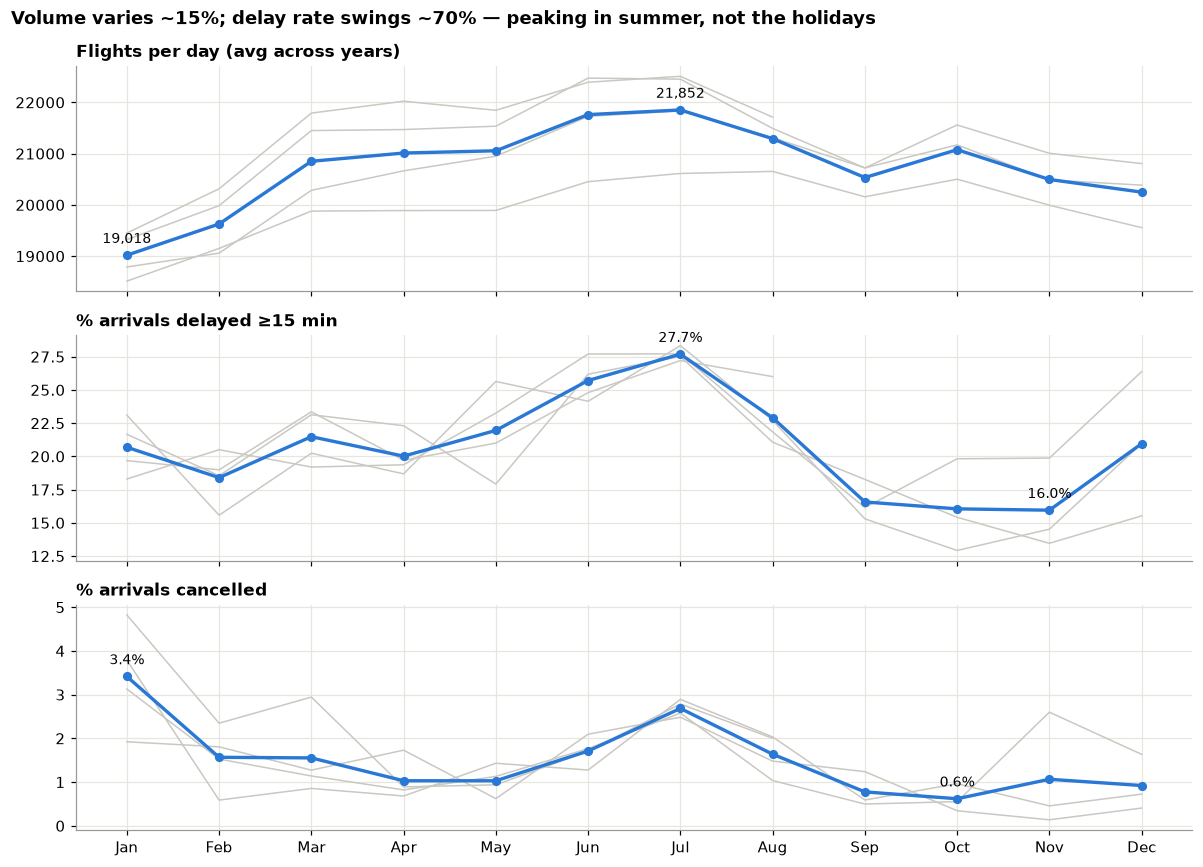

In [ ]:
# Small multiples sharing the x-axis (never a dual-axis chart)
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
x = np.arange(1, 13)
series = [("flights_per_day", "Flights per day (avg across years)", "#2a78d6", "{:,.0f}"),
          ("delay_rate", "% arrivals delayed ≥15 min", "#2a78d6", "{:.1f}%"),
          ("cancel_rate", "% arrivals cancelled", "#2a78d6", "{:.1f}%")]
for ax, (col, title, color, fmt) in zip(axes, series):
    for y, g in ym.groupby("year"):       # faint per-year lines show spread
        ax.plot(g.month, g[col], color="#c9c8c2", lw=1)
    ax.plot(x, mp[col], color=color, lw=2.2, marker="o", ms=5)
    for mm in (mp[col].idxmax(), mp[col].idxmin()):
        ax.annotate(fmt.format(mp[col][mm]), (mm, mp[col][mm]), textcoords="offset points",
                    xytext=(0, 8), ha="center", fontsize=9)
    ax.set_title(title, fontsize=11)
axes[-1].set_xticks(x, MONTHS)
fig.suptitle("Volume varies ~15%; delay rate swings ~70% — peaking in summer, not the holidays",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()


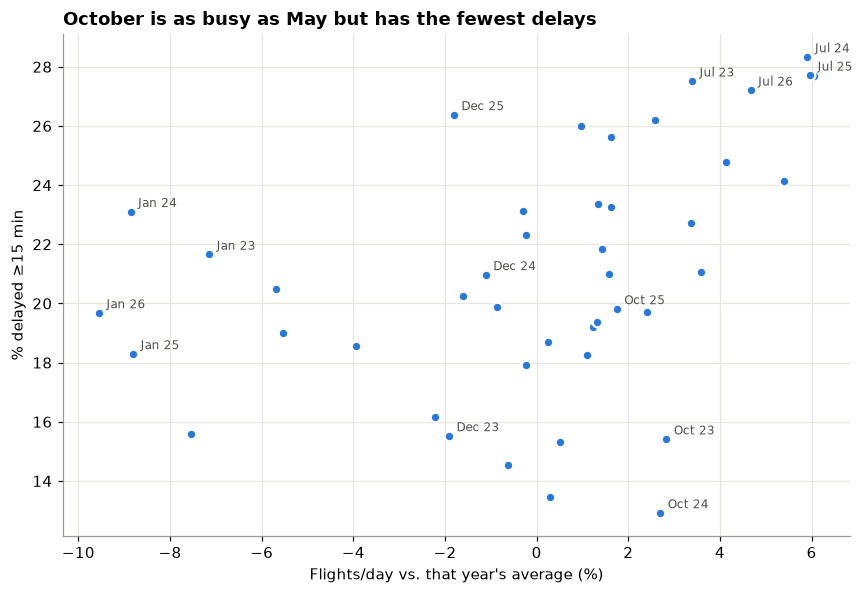

In [ ]:
# Busy ≠ delayed: each dot is one month of one year
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(ym.volume_vs_year_avg, ym.delay_rate, s=40, color="#2a78d6", edgecolor="white", linewidth=1.5)
for _, r in ym.iterrows():
    if r.month in (7, 10, 12, 1):
        ax.annotate(f"{MONTHS[int(r.month)-1]} {str(int(r.year))[2:]}", (r.volume_vs_year_avg, r.delay_rate),
                    textcoords="offset points", xytext=(5, 3), fontsize=8, color="#52514e")
ax.set_xlabel("Flights/day vs. that year's average (%)"); ax.set_ylabel("% delayed ≥15 min")
ax.set_title("October is as busy as May but has the fewest delays")
plt.tight_layout(); plt.show()


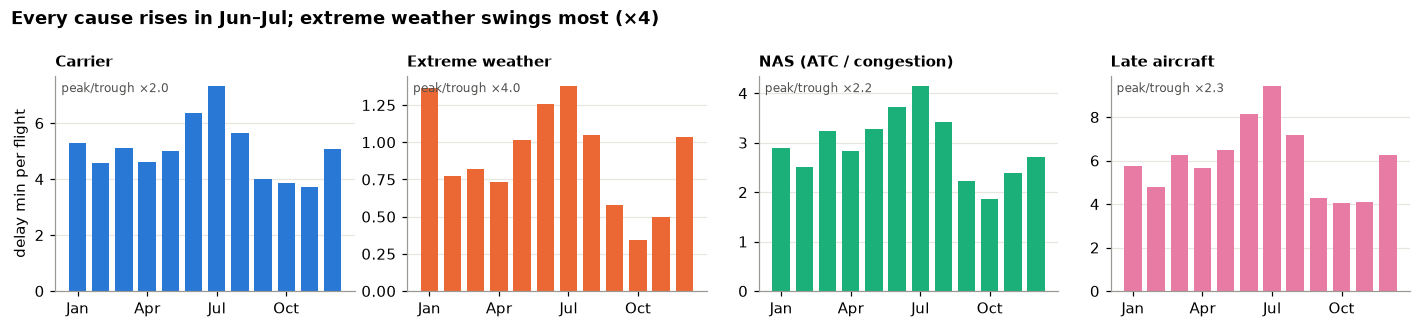

In [ ]:
# What *drives* the seasonal swing? Minutes of delay per flight, by cause and month
cm = mp[[c + "_mpf" for c in CAUSES]]
MAIN = [c for c in CAUSES if c != "security"]   # security is ~0.2% of minutes — pure noise here
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=False)
for ax, c in zip(axes, MAIN):
    ax.bar(x, cm[c + "_mpf"], color=COLORS[c], width=0.75)
    ax.set_title(LABELS[c], fontsize=10); ax.set_xticks([1, 4, 7, 10], ["Jan", "Apr", "Jul", "Oct"])
    ax.grid(axis="x", visible=False)
    ratio = cm[c + "_mpf"].max() / cm[c + "_mpf"].min()
    ax.text(0.02, 0.97, f"peak/trough ×{ratio:.1f}", transform=ax.transAxes, va="top", fontsize=8, color="#52514e")
axes[0].set_ylabel("delay min per flight")
fig.suptitle("Every cause rises in Jun–Jul; extreme weather swings most (×4)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()


**Takeaways**
- Volume is fairly flat (~19k–22k flights/day). Delay rate swings from ~16% (Sep–Nov) to ~28% (Jul).
- Volume and delay rate are only moderately correlated (r ≈ 0.4). **October** is a clean counter-example: high volume, lowest delays.
- **December** is the one place holiday travel shows: delays jump from ~16% in Nov to ~21% in Dec (Dec 2025 hit 26%) even though volume *drops* — winter weather hitting a full schedule with no slack.
- Summer is the worst season: convective thunderstorms + max volume + stretched crews → cascading late aircraft.
- Winter's damage shows up as **cancellations** (Jan ≈ 3.4%, the highest), which `arr_del15` does not count. A dashboard that only shows "delays" will hide winter. Show delay *and* cancellation rate.
- Outliers worth annotating: **Jul 2024** (Delta/Endeavor cancellations 6.6–8%, consistent with the CrowdStrike IT outage), **Jan 2024 / Jan 2026** cancellation spikes (winter storms — verify the specific events before captioning).

## RQ3 — Which airports experience the most delays (without drawing a population map)?

Counting delayed flights just ranks airports by size: the top 30 airports carry 63.6% of flights and 63.8% of delays. Four fixes:
1. **Rate, not count** — % of arrivals delayed.
2. **Volume floor** — airports with a few hundred flights swing from 5% to 38% by noise; keep ≥100k arrivals (55 airports) or shrink small ones.
3. **Carrier-mix adjustment** — an airport dominated by a high-delay airline looks bad through no fault of its own. Compare each airport's delays to what its airlines achieve nationally *in the same month* → **excess delay (percentage points)**.
4. **Cause fingerprint** — NAS minutes per flight is the most airport-attributable cause (runways, airspace, ATC).

In [ ]:
# Expected delays if each carrier performed at its national rate for that month
cmr = df.groupby(["carrier", "year", "month"])[["arr_flights", "arr_del15"]].sum()
cmr["exp_rate"] = cmr.arr_del15 / cmr.arr_flights
d = df.join(cmr["exp_rate"], on=["carrier", "year", "month"])
d["exp_del"] = d.exp_rate * d.arr_flights

ap = d.groupby("airport").agg(name=("airport_name", "first"), flights=("arr_flights", "sum"),
                              delayed=("arr_del15", "sum"), exp_del=("exp_del", "sum"),
                              cancelled=("arr_cancelled", "sum"), minutes=("arr_delay", "sum"),
                              **{m: (m, "sum") for m in MINS})
ap["city"] = ap.name.str.split(":").str[0]
ap["delay_rate"] = ap.delayed / ap.flights * 100
ap["excess_pp"] = (ap.delayed - ap.exp_del) / ap.flights * 100
ap["cancel_rate"] = ap.cancelled / ap.flights * 100
for c, m in zip(CAUSES, MINS):
    ap[c + "_mpf"] = ap[m] / ap.flights
    ap[c + "_share"] = ap[m] / ap.minutes * 100
ap["size_rank"] = ap.flights.rank(ascending=False).astype(int)

top30 = ap.nlargest(30, "flights")
print(f"Top 30 airports: {top30.flights.sum()/ap.flights.sum():.1%} of flights, "
      f"{top30.delayed.sum()/ap.delayed.sum():.1%} of delays  ← the population-map problem")
big = ap[ap.flights >= 100_000].copy()
print(f"{len(big)} airports with ≥100k arrivals")
print("corr(log size, delay rate) =", round(np.log(big.flights).corr(big.delay_rate), 2))
display(big.sort_values("excess_pp", ascending=False)
        [["city", "size_rank", "delay_rate", "excess_pp", "cancel_rate", "nas_share", "weather_share"]].head(12).round(1))


Top 30 airports: 63.6% of flights, 63.8% of delays  ← the population-map problem
55 airports with ≥100k arrivals
corr(log size, delay rate) = -0.11


,city,size_rank,delay_rate,excess_pp,cancel_rate,nas_share,weather_share
airport,,,,,,,
SFO,"San Francisco, CA",15,27.6,6.8,1.1,38.0,4.0
PBI,"West Palm Beach/Palm Beach, FL",54,25.9,3.2,1.8,27.7,3.6
SAN,"San Diego, CA",24,24.5,3.1,1.1,24.8,4.1
SJU,"San Juan, PR",49,27.8,2.8,1.3,19.7,4.2
JAX,"Jacksonville, FL",51,24.2,2.5,1.7,16.2,5.1
MKE,"Milwaukee, WI",53,23.1,2.3,1.8,13.5,7.2
FLL,"Fort Lauderdale, FL",26,25.9,2.3,1.9,27.3,3.3
BOS,"Boston, MA",14,24.0,2.0,2.0,28.0,3.7
LGA,"New York, NY",11,21.6,1.9,3.4,33.5,5.6


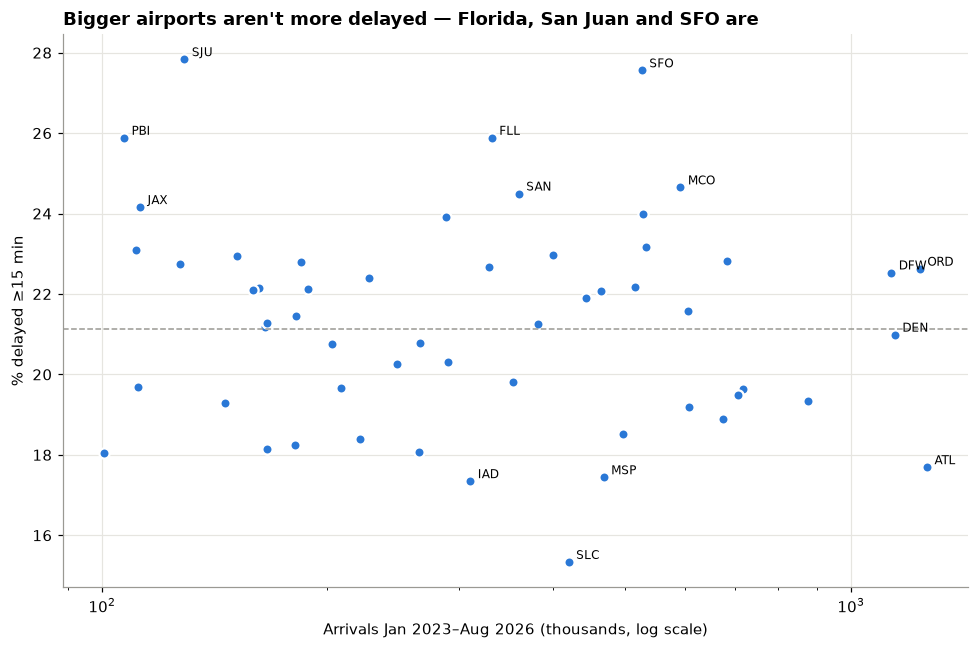

In [ ]:
# Size does not predict delay rate
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(big.flights / 1e3, big.delay_rate, s=45, color="#2a78d6", edgecolor="white", linewidth=1.5)
ax.set_xscale("log")
for code, r in big.iterrows():
    if r.delay_rate > 24 or r.delay_rate < 17.5 or r.size_rank <= 4:
        ax.annotate(code, (r.flights / 1e3, r.delay_rate), textcoords="offset points", xytext=(5, 2), fontsize=8)
ax.axhline(df.arr_del15.sum() / df.arr_flights.sum() * 100, color="#9a9993", lw=1, ls="--")
ax.set_xlabel("Arrivals Jan 2023–Aug 2026 (thousands, log scale)"); ax.set_ylabel("% delayed ≥15 min")
ax.set_title("Bigger airports aren't more delayed — Florida, San Juan and SFO are")
plt.tight_layout(); plt.show()


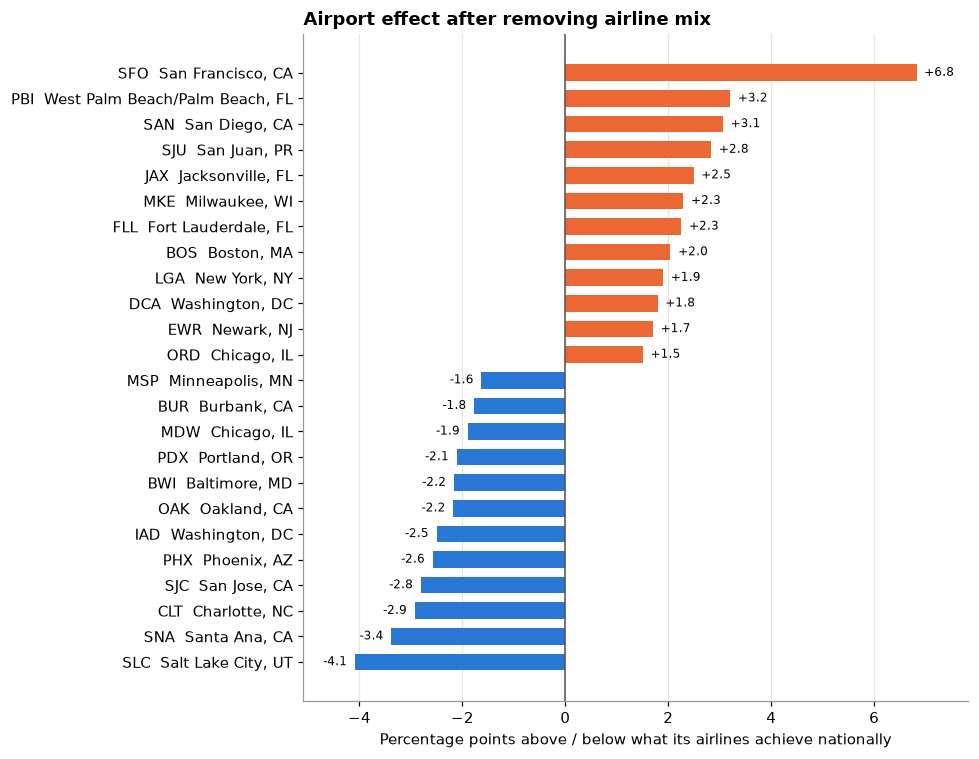

In [ ]:
# Excess delay vs carrier-mix expectation — diverging bars, top & bottom 12
ex = pd.concat([big.nlargest(12, "excess_pp"), big.nsmallest(12, "excess_pp")]).sort_values("excess_pp")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh([f"{c}  {n}" for c, n in zip(ex.index, ex.city)], ex.excess_pp, height=0.65,
        color=np.where(ex.excess_pp > 0, "#eb6834", "#2a78d6"))
for i, v in enumerate(ex.excess_pp):
    ax.text(v + (0.15 if v > 0 else -0.15), i, f"{v:+.1f}", va="center", ha="left" if v > 0 else "right", fontsize=8)
ax.axvline(0, color="#52514e", lw=1); ax.grid(axis="y", visible=False)
ax.set_xlim(ex.excess_pp.min() - 1, ex.excess_pp.max() + 1)
ax.set_xlabel("Percentage points above / below what its airlines achieve nationally")
ax.set_title("Airport effect after removing airline mix")
plt.tight_layout(); plt.show()


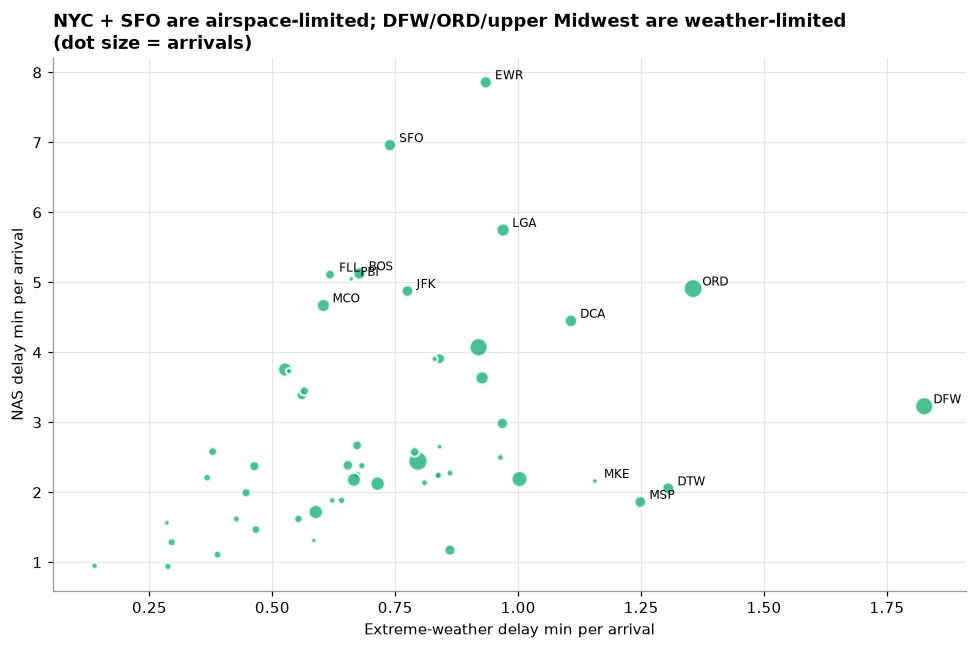

In [ ]:
# Cause fingerprint: NAS (airport/airspace) vs extreme-weather minutes per flight
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(big.weather_mpf, big.nas_mpf, s=big.flights / 8000, color="#1baf7a", alpha=0.8,
           edgecolor="white", linewidth=1.5)
for code, r in big.iterrows():
    if r.nas_mpf > 4.3 or r.weather_mpf > 1.15:
        ax.annotate(code, (r.weather_mpf, r.nas_mpf), textcoords="offset points", xytext=(6, 2), fontsize=8)
ax.set_xlabel("Extreme-weather delay min per arrival"); ax.set_ylabel("NAS delay min per arrival")
ax.set_title("NYC + SFO are airspace-limited; DFW/ORD/upper Midwest are weather-limited\n(dot size = arrivals)")
plt.tight_layout(); plt.show()


**Takeaways**
- Size does not predict delay *rate* (r ≈ −0.1 on log size among the 55 large airports) — so a rate map is genuinely **not** a population map.
- **SFO** is the stand-out: +6.8 pp above its airline mix, 38% of its minutes are NAS (fog + closely spaced parallel runways cut arrival rates).
- **Florida** (FLL, PBI, MCO, TPA, JAX, MIA) and **San Juan** cluster high — summer thunderstorms and crowded airspace.
- **EWR / LGA / JFK** lead NAS minutes per flight and have the highest cancellation rates (~3%) — capacity-constrained airspace.
- Several hubs beat their own airlines' national average: **SLC (−4.1), CLT (−2.9), PHX (−2.6), IAD (−2.5), MSP (−1.6)**. ATL has the most arrivals in the dataset yet sits at −1.6.
- Rankings are fairly stable year to year (rank correlation 0.55–0.76), so this isn't noise.

In [ ]:
# Export tidy tables for the dashboard
import os
os.makedirs("data/processed", exist_ok=True)
tot.reset_index(names="cause").to_csv("data/processed/causes_overall.csv", index=False)
car.assign(**{c + "_share": mix[m] for c, m in zip(CAUSES, MINS)}).to_csv("data/processed/carriers.csv")
ym.to_csv("data/processed/monthly.csv", index=False)
ap.drop(columns=["name"]).to_csv("data/processed/airports.csv")
print("wrote", os.listdir("data/processed"))


wrote ['causes_overall.csv', 'airports.csv', 'carriers.csv', 'monthly.csv']
